### DATA ANALYSIS

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Project directory
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Dataset location
DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "segments.csv"
)

# Check file exists
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}"
    )

# Load original telemetry
df = pd.read_csv(
    DATA_PATH,
    low_memory=False
)

print("Successfully loaded OPSSAT-AD")

print("Dataset shape:", df.shape)

display(df.head(10))

Successfully loaded OPSSAT-AD
Dataset shape: (303493, 8)


,channel,timestamp,value,label,sampling,anomaly,segment,train
0,CADC0872,2022-06-01T23:42:54.000Z,-0.000021,anomaly,1,1,1,1
1,CADC0872,2022-06-01T23:42:55.000Z,-0.000021,anomaly,1,1,1,1
2,CADC0872,2022-06-01T23:42:56.000Z,-0.000021,anomaly,1,1,1,1
3,CADC0872,2022-06-01T23:42:57.000Z,-0.000021,anomaly,1,1,1,1
4,CADC0872,2022-06-01T23:42:58.000Z,-0.000021,anomaly,1,1,1,1
5,CADC0872,2022-06-01T23:42:59.000Z,-0.000021,anomaly,1,1,1,1
6,CADC0872,2022-06-01T23:43:00.000Z,-0.000021,anomaly,1,1,1,1
7,CADC0872,2022-06-01T23:43:01.000Z,-0.000021,anomaly,1,1,1,1
8,CADC0872,2022-06-01T23:43:02.000Z,-0.000021,anomaly,1,1,1,1
9,CADC0872,2022-06-01T23:43:03.000Z,-0.000021,anomaly,1,1,1,1


In [7]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
display(
    df.dtypes.to_frame("dtype")
)

print("\nMissing values:")
display(
    df.isna().sum().to_frame("missing_values")
)

print("\nUnique channels:")
print(df["channel"].nunique())

print(df["channel"].value_counts())

print("\nLabel distribution:")
print(df["label"].value_counts(dropna=False))

print("\nOfficial training/test flag:")
print(df["train"].value_counts(dropna=False))

print("Textual label distribution:")
display(df["label"].value_counts(dropna=False))

print("\nNumerical anomaly distribution:")
display(df["anomaly"].value_counts(dropna=False))

print("\nRelationship between the two:")
display(
    pd.crosstab(
        df["label"],
        df["anomaly"]
    )
)

Column names:
['channel', 'timestamp', 'value', 'label', 'sampling', 'anomaly', 'segment', 'train', 'value_numeric', 'timestamp_parsed', 'sampling_numeric']

Data types:


,dtype
channel,str
timestamp,str
value,float64
label,str
sampling,int64
anomaly,int64
segment,int64
train,int64
value_numeric,float64
timestamp_parsed,"datetime64[us, UTC]"



Missing values:


,missing_values
channel,0
timestamp,0
value,0
label,0
sampling,0
anomaly,0
segment,0
train,0
value_numeric,0
timestamp_parsed,0



Unique channels:
9
channel
CADC0873    68289
CADC0872    66819
CADC0874    58719
CADC0892    49782
CADC0894    35512
CADC0884    11810
CADC0888    11640
CADC0890      549
CADC0886      373
Name: count, dtype: int64

Label distribution:
label
anomaly    303493
Name: count, dtype: int64

Official training/test flag:
train
1    225178
0     78315
Name: count, dtype: int64
Textual label distribution:


label
anomaly    303493
Name: count, dtype: int64


Numerical anomaly distribution:


anomaly
0    203229
1    100264
Name: count, dtype: int64


Relationship between the two:


anomaly,0,1
label,,
anomaly,203229,100264


In [8]:
segment_channel_counts = (
    df.groupby("segment")["channel"].nunique()
)

print(
    "Unique segment IDs:",
    df["segment"].nunique()
)

print(
    "Segment IDs associated with multiple channels:",
    (segment_channel_counts > 1).sum()
)

assert segment_channel_counts.max() == 1

Unique segment IDs: 2123
Segment IDs associated with multiple channels: 0


#### Reconstruct the individual telemetry segments

In [9]:
# Convert numerical values
df["value_numeric"] = pd.to_numeric(
    df["value"],
    errors="coerce"
)

# Parse timestamps
df["timestamp_parsed"] = pd.to_datetime(
    df["timestamp"],
    errors="coerce",
    utc=True
)

# Convert sampling information where possible
df["sampling_numeric"] = pd.to_numeric(
    df["sampling"],
    errors="coerce"
)

segment_summary = (

    df.groupby("segment")

    .agg(

        channel=("channel", "first"),

        n_samples=("value", "size"),

        n_missing_values=(
            "value",
            lambda x: x.isna().sum()
        ),

        # Textual label: retained for auditing only
        text_label=("label", "first"),

        # Actual numerical anomaly target
        anomaly=("anomaly", "first"),

        n_unique_anomaly=("anomaly", "nunique"),

        train=("train", "first"),

        n_unique_train=("train", "nunique"),

        sampling=("sampling", "first"),

        n_unique_sampling=("sampling", "nunique"),

        timestamp_start=("timestamp_parsed", "min"),

        timestamp_end=("timestamp_parsed", "max"),

        sampling_min=("sampling_numeric", "min"),

        sampling_max=("sampling_numeric", "max")

    )

    .reset_index()

)

print("Total reconstructed segments:", len(segment_summary))

display(segment_summary.head(10))

Total reconstructed segments: 2123


,segment,channel,n_samples,n_missing_values,text_label,anomaly,n_unique_anomaly,train,n_unique_train,sampling,n_unique_sampling,timestamp_start,timestamp_end,sampling_min,sampling_max
0,1,CADC0872,280,0,anomaly,1,1,1,1,1,1,2022-06-01 23:42:54+00:00,2022-06-01 23:47:33+00:00,1,1
1,2,CADC0872,477,0,anomaly,1,1,1,1,1,1,2022-06-01 23:47:34+00:00,2022-06-01 23:55:30+00:00,1,1
2,3,CADC0872,595,0,anomaly,1,1,1,1,1,1,2022-06-01 23:55:31+00:00,2022-06-02 00:05:25+00:00,1,1
3,4,CADC0872,272,0,anomaly,1,1,1,1,1,1,2022-06-02 00:05:26+00:00,2022-06-02 00:09:57+00:00,1,1
4,5,CADC0872,257,0,anomaly,0,1,0,1,1,1,2022-06-02 00:09:58+00:00,2022-06-02 00:14:14+00:00,1,1
5,6,CADC0872,253,0,anomaly,0,1,1,1,1,1,2022-06-02 00:14:15+00:00,2022-06-02 00:18:27+00:00,1,1
6,7,CADC0872,380,0,anomaly,0,1,0,1,1,1,2022-06-02 00:18:28+00:00,2022-06-02 00:24:47+00:00,1,1
7,8,CADC0872,400,0,anomaly,1,1,1,1,1,1,2022-06-02 00:24:48+00:00,2022-06-02 00:31:27+00:00,1,1
8,9,CADC0872,514,0,anomaly,1,1,1,1,1,1,2022-06-02 00:31:28+00:00,2022-06-02 00:40:01+00:00,1,1
9,10,CADC0872,317,0,anomaly,0,1,1,1,1,1,2022-06-02 00:40:02+00:00,2022-06-02 00:45:18+00:00,1,1


In [11]:
inconsistent_segments = segment_summary[
    (segment_summary["n_unique_anomaly"] > 1)
    |
    (segment_summary["n_unique_train"] > 1)
]

print(
    "Segments with inconsistent labels or split assignments:",
    len(inconsistent_segments)
)

display(inconsistent_segments.head(10))

print(
    "\nMissing telemetry values:",
    df["value_numeric"].isna().sum()
)

print(
    "Invalid timestamps:",
    df["timestamp_parsed"].isna().sum()
)

print(
    "Segments with inconsistent anomaly labels:",
    (segment_summary["n_unique_anomaly"] > 1).sum()
)

print(
    "Segments with inconsistent train assignments:",
    (segment_summary["n_unique_train"] > 1).sum()
)

print(
    "Segments with inconsistent sampling values:",
    (segment_summary["n_unique_sampling"] > 1).sum()
)

print(
    "Unique anomaly labels:",
    sorted(segment_summary["anomaly"].unique())
)

assert segment_summary["n_unique_anomaly"].eq(1).all()

assert segment_summary["n_unique_train"].eq(1).all()

assert set(segment_summary["anomaly"].unique()) == {0, 1}

assert set(segment_summary["train"].unique()) == {0, 1}

print("\nSegment validation completed.")

Segments with inconsistent labels or split assignments: 0


,segment,channel,n_samples,n_missing_values,text_label,anomaly,n_unique_anomaly,train,n_unique_train,sampling,n_unique_sampling,timestamp_start,timestamp_end,sampling_min,sampling_max



Missing telemetry values: 0
Invalid timestamps: 0
Segments with inconsistent anomaly labels: 0
Segments with inconsistent train assignments: 0
Segments with inconsistent sampling values: 0
Unique anomaly labels: [np.int64(0), np.int64(1)]

Segment validation completed.


In [12]:
global_distribution = pd.crosstab(
    segment_summary["train"],
    segment_summary["anomaly"]
)

global_distribution = global_distribution.reindex(
    index=[1, 0],
    columns=[0, 1],
    fill_value=0
)

global_distribution.index = [
    "Training",
    "Test"
]

global_distribution.columns = [
    "Nominal",
    "Anomalous"
]

display(global_distribution)

print("\nTotal segments:", len(segment_summary))

,Nominal,Anomalous
Training,1273,321
Test,416,113



Total segments: 2123


In [13]:
assert global_distribution.loc["Training", "Nominal"] == 1273

assert global_distribution.loc["Training", "Anomalous"] == 321

assert global_distribution.loc["Test", "Nominal"] == 416

assert global_distribution.loc["Test", "Anomalous"] == 113

print("Official benchmark split reproduced successfully.")

Official benchmark split reproduced successfully.


In [14]:
channel_distribution = pd.crosstab(
    segment_summary["channel"],
    segment_summary["anomaly"]
).reindex(
    columns=[0, 1],
    fill_value=0
)

channel_distribution.columns = [
    "n_nominal",
    "n_anomalous"
]

channel_distribution["n_total"] = (
    channel_distribution["n_nominal"]
    + channel_distribution["n_anomalous"]
)

channel_distribution["anomaly_rate"] = (
    channel_distribution["n_anomalous"]
    / channel_distribution["n_total"]
)

display(
    channel_distribution.sort_values(
        "n_total",
        ascending=False
    ).round(3)
)

,n_nominal,n_anomalous,n_total,anomaly_rate
channel,,,,
CADC0873,488,105,593,0.177
CADC0872,415,131,546,0.240
CADC0888,192,60,252,0.238
CADC0892,177,34,211,0.161
CADC0874,125,69,194,0.356
CADC0884,158,0,158,0.000
CADC0894,123,21,144,0.146
CADC0890,3,11,14,0.786
CADC0886,8,3,11,0.273


In [15]:
channel_split_distribution = pd.crosstab(
    [
        segment_summary["channel"],
        segment_summary["train"]
    ],
    segment_summary["anomaly"]
).reindex(
    columns=[0, 1],
    fill_value=0
)

channel_split_distribution.columns = [
    "nominal",
    "anomalous"
]

display(channel_split_distribution)

nominal  anomalous
channel  train                    
CADC0872 0          100         32
         1          315         99
CADC0873 0          122         31
         1          366         74
CADC0874 0           29         23
         1           96         46
CADC0884 0           36          0
         1          122          0
CADC0886 0            3          1
         1            5          2
CADC0888 0           52         12
         1          140         48
CADC0890 0            0          2
         1            3          9
CADC0892 0           46          7
         1          131         27
CADC0894 0           28          5
         1           95         16

In [16]:
sampling_summary = (
    segment_summary
    .groupby("channel")
    .agg(
        n_segments=("segment", "count"),
        min_sampling=("sampling_min", "min"),
        max_sampling=("sampling_max", "max"),
        median_sampling=("sampling", "median"),
        inconsistent_sampling_segments=(
            "n_unique_sampling",
            lambda x: (x > 1).sum()
        )
    )
)

display(sampling_summary)

,n_segments,min_sampling,max_sampling,median_sampling,inconsistent_sampling_segments
channel,,,,,
CADC0872,546,1,5,5.0,0
CADC0873,593,1,5,5.0,0
CADC0874,194,1,5,5.0,0
CADC0884,158,5,5,5.0,0
CADC0886,11,5,5,5.0,0
CADC0888,252,5,5,5.0,0
CADC0890,14,5,5,5.0,0
CADC0892,211,1,5,1.0,0
CADC0894,144,1,5,5.0,0


This means that sampling is constant within each segment, but differs between segments.

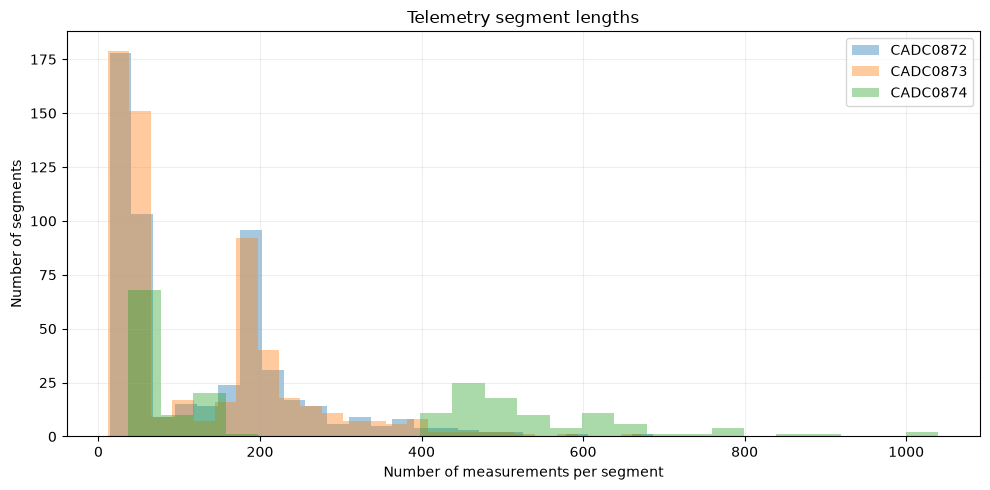

In [17]:
fig, ax = plt.subplots(figsize=(10, 5))

for channel in ["CADC0872", "CADC0873", "CADC0874"]:

    values = segment_summary.loc[
        segment_summary["channel"] == channel,
        "n_samples"
    ]

    ax.hist(
        values,
        bins=25,
        alpha=0.4,
        label=channel
    )

ax.set_title("Telemetry segment lengths")

ax.set_xlabel("Number of measurements per segment")

ax.set_ylabel("Number of segments")

ax.legend()

ax.grid(alpha=0.2)

plt.tight_layout()

figures_dir = PROJECT_ROOT / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures_dir / "segment_length_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Sampling-rate investigation
Changes in sampling frequency

In [18]:
selected_channel = "CADC0872"

channel_data = segment_summary[
    segment_summary["channel"] == selected_channel
].copy()

sampling_distribution = pd.crosstab(
    [
        channel_data["sampling"],
        channel_data["train"]
    ],
    channel_data["anomaly"]
).reindex(
    columns=[0, 1],
    fill_value=0
)

sampling_distribution.columns = [
    "nominal",
    "anomalous"
]

display(sampling_distribution)

nominal  anomalous
sampling train                    
1        0           34         17
         1          106         61
5        0           66         15
         1          209         38

In [19]:
def inspect_segment_timing(segment_id):

    segment_df = (
        df[df["segment"] == segment_id]
        .sort_values("timestamp_parsed")
    )

    time_differences = (
        segment_df["timestamp_parsed"]
        .diff()
        .dt.total_seconds()
        .dropna()
    )

    expected_sampling = segment_df["sampling"].iloc[0]

    return {
        "segment": segment_id,

        "sampling_seconds": expected_sampling,

        "median_actual_interval":
            time_differences.median(),

        "minimum_actual_interval":
            time_differences.min(),

        "maximum_actual_interval":
            time_differences.max(),

        "proportion_matching_sampling":
            np.isclose(
                time_differences,
                expected_sampling
            ).mean()
    }

In [20]:
example_segments = (
    channel_data
    .groupby("sampling")["segment"]
    .first()
    .tolist()
)

timing_results = pd.DataFrame([
    inspect_segment_timing(segment_id)
    for segment_id in example_segments
])

display(timing_results.round(3))

,segment,sampling_seconds,median_actual_interval,minimum_actual_interval,maximum_actual_interval,proportion_matching_sampling
0,1,1,1.0,1.0,1.0,1.0
1,1796,5,5.0,5.0,5.0,1.0


#### Visualise actual telemetry

In [21]:
selected_sampling = int(
    channel_data["sampling"].mode().iloc[0]
)

print("Selected sampling interval:", selected_sampling)

training_segments = channel_data[
    (channel_data["train"] == 1) &
    (channel_data["sampling"] == selected_sampling)
].copy()

print(
    training_segments["anomaly"]
    .value_counts()
)

Selected sampling interval: 5
anomaly
0    209
1     38
Name: count, dtype: int64


In [22]:
representative_segments = []

for anomaly_label in [0, 1]:

    candidates = (
        training_segments[
            training_segments["anomaly"] == anomaly_label
        ]
        .sort_values("n_samples")
        .reset_index(drop=True)
    )

    if candidates.empty:
        raise ValueError(
            f"No examples for anomaly={anomaly_label}"
        )

    selected = candidates.iloc[
        len(candidates) // 2
    ]

    representative_segments.append(selected)

display(
    pd.DataFrame(representative_segments)[
        [
            "segment",
            "anomaly",
            "sampling",
            "n_samples",
            "timestamp_start",
            "timestamp_end"
        ]
    ]
)

,segment,anomaly,sampling,n_samples,timestamp_start,timestamp_end
104,1885,0,5,21,2022-01-04 21:43:00+00:00,2022-01-04 21:44:40+00:00
19,1969,1,5,58,2022-01-27 02:41:51+00:00,2022-01-27 02:47:26+00:00


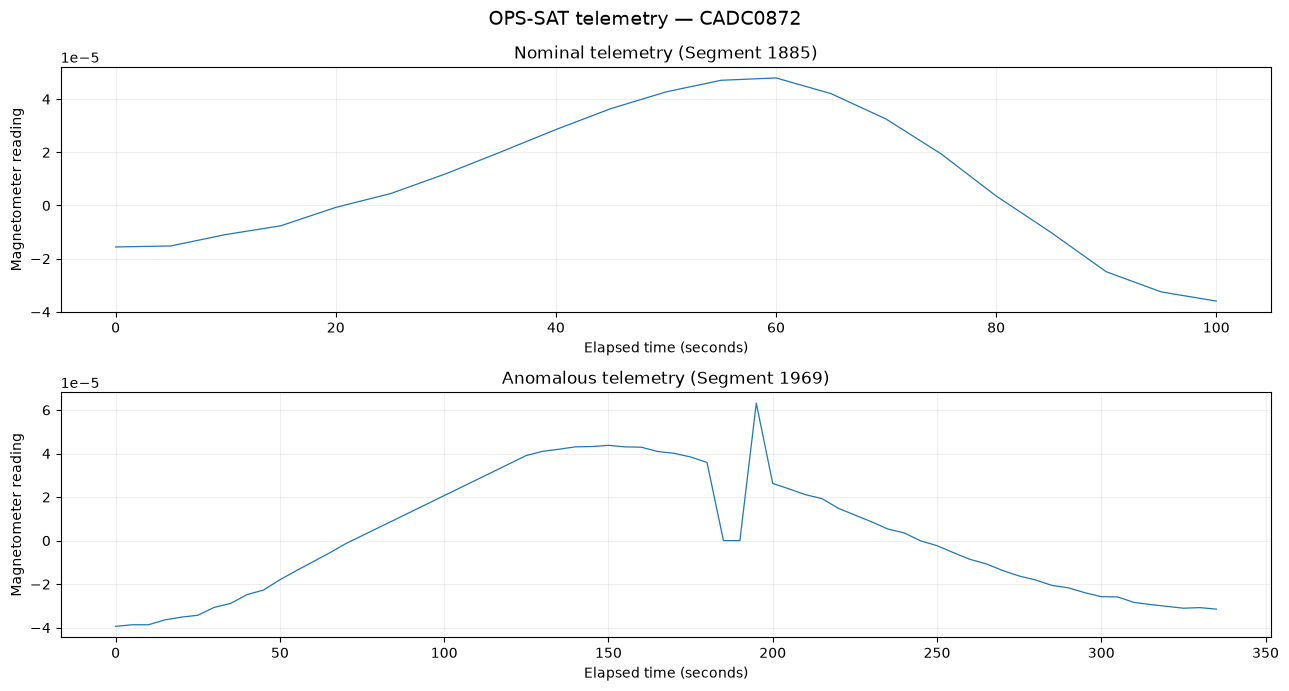

In [23]:
fig, axes = plt.subplots(
    2,
    1,
    figsize=(13, 7)
)

titles = {
    0: "Nominal telemetry",
    1: "Anomalous telemetry"
}

for ax, selected in zip(
    axes,
    representative_segments
):

    segment_id = selected["segment"]

    segment_df = (
        df[df["segment"] == segment_id]
        .sort_values("timestamp_parsed")
        .copy()
    )

    elapsed_seconds = (
        segment_df["timestamp_parsed"]
        - segment_df["timestamp_parsed"].iloc[0]
    ).dt.total_seconds()

    ax.plot(
        elapsed_seconds,
        segment_df["value_numeric"],
        linewidth=0.9
    )

    ax.set_title(
        f"{titles[selected['anomaly']]} "
        f"(Segment {segment_id})"
    )

    ax.set_xlabel("Elapsed time (seconds)")

    ax.set_ylabel("Magnetometer reading")

    ax.grid(alpha=0.2)

fig.suptitle(
    f"OPS-SAT telemetry — {selected_channel}",
    fontsize=14
)

plt.tight_layout()

figures_dir = PROJECT_ROOT / "reports" / "figures"

figures_dir.mkdir(
    parents=True,
    exist_ok=True
)

fig.savefig(
    figures_dir / "opssat_representative_telemetry.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()